# FL-ATTACK-003.1 — Backdoor attack and defenses

*Epic EPIC-001 · story fl_attack_003 · all results below are loaded from files produced by the task's experiment function and labelled MEASURED/SIMULATED; clients are virtual; data is synthetic.*

## 1. Research objective
Measure backdoor attack success (trigger + poisoning + boosting) at three intensities and defence effect.

## 2. Scientific background
Backdoors embed a trigger-conditioned behaviour while keeping clean accuracy [bagdasaryan2020, sun2019, wang2020tail].

References use keys of `docs/references/references_master.md` (status per entry).

## 3. Research questions
- **RQ1.** How does ASR grow with attacker fraction/boost?
- **RQ2.** What is the ASR of the trigger on a clean model?

## 4. Hypotheses
- **H1.** ASR rises with intensity; secure aggregation does not reduce it.

## 5. Mathematical formulation
ASR = P(f(x⊕t)=y_target | y≠y_target); poisoned local objective L_clean + L_poison; boosting Δ' = γΔ.

## 6. Experimental environment

In [1]:
import os, sys, json, platform, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
os.environ.setdefault("MLFLOW_DISABLE_AGENT_HINT", "1")
def _find_root():
    p = Path(os.environ.get("FL_ROOT") or os.environ.get("RS_ROOT") or Path.cwd()).resolve()
    for q in [p, *p.parents]:
        if (q / "src" / "federated_learning").exists():
            return q
    raise RuntimeError("repository root not found; set RS_ROOT")
ROOT = _find_root()
sys.path.insert(0, str(ROOT / "src"))
STORY = "fl_attack_003"
_cands = [ROOT / "experiments" / "results" / STORY]
RES = next(c for c in _cands if c.exists())
import numpy as np, pandas as pd
import matplotlib; matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import Image, display
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
SEED = 0; np.random.seed(SEED)
def show_csv(name, n=12):
    p = RES / name
    if p.exists(): display(pd.read_csv(p).round(4).head(n))
    else: print("MISSING", name)
def show_fig(name):
    for base in (RES / "figures", RES):
        if (base / name).exists(): display(Image(filename=str(base / name))); return
    print("MISSING figure", name)
print("root:", ROOT, "| results:", RES)

root: /home/claude/fl_sprint | results: /home/claude/fl_sprint/experiments/results/fl_attack_003


In [2]:
import importlib.metadata as md
vers = {}
for p in ["numpy","scipy","scikit-learn","torch","tenseal","phe","pandas","matplotlib","cryptography","psutil","mlflow","opacus"]:
    try: vers[p] = md.version(p)
    except Exception: vers[p] = "not installed"
print(json.dumps(dict(python=platform.python_version(), platform=platform.platform(), versions=vers, seed=SEED, gpu="none (CPU only; GPU metrics NOT_MEASURED)"), indent=1))

{
 "python": "3.13.18",
 "platform": "Linux-6.18.44-fc-v338-x86_64-with-glibc2.39",
 "versions": {
  "numpy": "2.5.3",
  "scipy": "1.18.1",
  "scikit-learn": "1.9.1",
  "torch": "2.15.0",
  "tenseal": "0.3.18",
  "phe": "1.5.0",
  "pandas": "3.0.5",
  "matplotlib": "3.11.2",
  "cryptography": "50.0.1",
  "psutil": "7.2.2",
  "mlflow": "3.18.0",
  "opacus": "1.6.0"
 },
 "seed": 0,
 "gpu": "none (CPU only; GPU metrics NOT_MEASURED)"
}


## 7. Dataset description
Synthetic binary tabular dataset **SYN-IDS-v1** (scikit-learn `make_classification`, 40 features, 70:30 split). Chosen because no real IDS/clinical dataset was available in the sandbox. It has no clinical meaning; conclusions about absolute accuracy do not transfer.

In [3]:
from federated_learning.synthetic_data.generators.syn_ids_v1 import make_dataset, DATASET_ID
from federated_learning.data_partitioning.iid import partition_iid
from federated_learning.data_partitioning.dirichlet import partition_dirichlet
from federated_learning.data_partitioning.metrics import label_skew_stat
data = make_dataset(n_samples=6000, seed=SEED)
print(DATASET_ID, "train", data.X_train.shape, "test", data.X_test.shape, "positive rate", float(data.y_train.mean()))
print("NOTE: SYNTHETIC tabular data (not CIC-IDS-2017, not patient data); clients are VIRTUAL, not hospitals.")

SYN-IDS-v1 train (4200, 40) test (1800, 40) positive rate 0.40095238095238095
NOTE: SYNTHETIC tabular data (not CIC-IDS-2017, not patient data); clients are VIRTUAL, not hospitals.


## 8. Configuration and reproducibility settings
Seeds are fixed; each stored result carries `provenance` (experiment id, SHA-256 of the configuration, environment versions; `git_commit` is `null` because the workspace is not a git repository).

In [4]:
from federated_learning.training.config import FLConfig
cfg = FLConfig(rounds=5, local_epochs=1, seed=SEED)
print(cfg)

FLConfig(algo='fedavg', rounds=5, local_epochs=1, lr=0.05, batch_size=32, participation=1.0, mu=0.0, hidden=32, act='relu', seed=0, hetero_epochs=False, eval_every=1, server_lr=1.0)


## 9. Data preparation
Partitioning into virtual clients (IID or Dirichlet label skew) is performed by `federated_learning.data_partitioning`.

In [5]:
parts_iid = partition_iid(data.y_train, 10, SEED)
parts_dir = partition_dirichlet(data.y_train, 10, 0.3, SEED)
print('label-skew statistic IID:', round(label_skew_stat(data.y_train, parts_iid),3), ' Dirichlet(0.3):', round(label_skew_stat(data.y_train, parts_dir),3))

label-skew statistic IID: 0.019  Dirichlet(0.3): 0.363


## 10. Implementation
Reusable code lives in `src/federated_learning/` (`attacks.py`, `defenses.py`, `fl.py`). The cell below exercises it live (small, fast, deterministic) and asserts correctness.

In [6]:
from federated_learning import attacks as A
from federated_learning.training.config import FLConfig
from federated_learning.servers.orchestrator import run_fl
parts = partition_iid(data.y_train, 10, SEED); rng = np.random.default_rng(SEED); mal = {0, 1, 2}
cd = {k: A.poison_client_data(data.X_train[parts[k]], data.y_train[parts[k]], 0.6, 0, rng)[:2] for k in mal}
ev = lambda m, w: A.backdoor_metrics(m, w, data.X_test, data.y_test, 0)
atk = run_fl(FLConfig(rounds=8, local_epochs=1, seed=SEED), data, parts, client_data=cd, client_hook=A.boost_hook(mal, 3.0), eval_fn=ev)
cln = run_fl(FLConfig(rounds=8, local_epochs=1, seed=SEED), data, parts, eval_fn=ev)
print("ASR attacked:", round(atk.final["asr"], 3), "| ASR clean model:", round(cln.final["asr"], 3)); assert atk.final["asr"] > cln.final["asr"]

ASR attacked: 1.0 | ASR clean model: 0.555


## 11. Experiment execution
The full experiment was executed by `python -m federated_learning.pipelines.experiments.run_all --task FL-ATTACK-003.1` (see `logs/`). Its raw per-run results are loaded here; they are not re-computed inside the notebook.

In [7]:
show_csv('task_3_1_runs.csv')
show_csv('task_3_1_grid.csv')
show_csv('task_3_1_trigger_selection.csv')

,level,seed,clean_acc,asr,asr_untriggered,mal_frac,poison_frac,boost
0,none(clean FL),0,0.7781,0.1174,0.3398,NaN,NaN,NaN
1,low,0,0.7725,0.8294,0.3729,0.1,0.2,1.0
2,medium,0,0.7408,0.9965,0.5815,0.2,0.5,3.0
3,high,0,0.6939,0.9993,0.7396,0.3,0.8,5.0
4,none(clean FL),1,0.7811,0.0097,0.3577,NaN,NaN,NaN
5,low,1,0.7725,0.6464,0.3971,0.1,0.2,1.0
6,medium,1,0.7422,0.9972,0.5863,0.2,0.5,3.0
7,high,1,0.6881,0.9986,0.7604,0.3,0.8,5.0
8,none(clean FL),2,0.7797,0.0110,0.3287,NaN,NaN,NaN
9,low,2,0.7714,0.7472,0.3695,0.1,0.2,1.0


,mal_client_frac,poison_sample_frac,asr,clean_acc
0,0.05,0.2,0.5407,0.7739
1,0.05,0.5,0.6602,0.7703
2,0.05,0.8,0.6602,0.7703
3,0.10,0.2,0.8294,0.7725
4,0.10,0.5,0.8978,0.7717
5,0.10,0.8,0.8978,0.7717
6,0.20,0.2,0.9669,0.7717
7,0.20,0.5,0.9834,0.7586
8,0.20,0.8,0.9834,0.7586
9,0.30,0.2,0.9883,0.7667


,trigger,clean_model_asr,clean_acc
0,f0-3=+4,0.3267,0.7781
1,f0-3=-4,0.3336,0.7781
2,f0-7=+2.5,0.9261,0.7781
3,f0-1=+6,0.1174,0.7781


## 12. Metrics collection
Metric definitions: MEASURED over seeds: attack metric (ASR / AUC / success rate), clean accuracy, defense cost. Intensity levels low/medium/high are defined in docs/fl_attack_003/attack_methodology.md.

In [8]:
show_csv('task_3_1_summary.csv')

,level,asr,asr_ci,clean_acc,clean_acc_ci,kpi_asr_lt_5pct
0,none(clean FL),0.0460,"[-0.107, 0.200]",0.7796,"[0.776, 0.783]",True
1,low,0.7410,"[0.513, 0.969]",0.7721,"[0.771, 0.774]",False
2,medium,0.9972,"[0.996, 0.999]",0.7415,"[0.740, 0.743]",False
3,high,0.9993,"[0.998, 1.001]",0.6902,"[0.682, 0.698]",False


## 13. Statistical analysis
95% CIs over seeds; AUC/ASR CIs may extend beyond [0,1] because they are t-intervals on few seeds (reported as computed).

In [9]:
show_csv('task_3_1_summary.csv', 30)

,level,asr,asr_ci,clean_acc,clean_acc_ci,kpi_asr_lt_5pct
0,none(clean FL),0.0460,"[-0.107, 0.200]",0.7796,"[0.776, 0.783]",True
1,low,0.7410,"[0.513, 0.969]",0.7721,"[0.771, 0.774]",False
2,medium,0.9972,"[0.996, 0.999]",0.7415,"[0.740, 0.743]",False
3,high,0.9993,"[0.998, 1.001]",0.6902,"[0.682, 0.698]",False


## 14. Visualizations

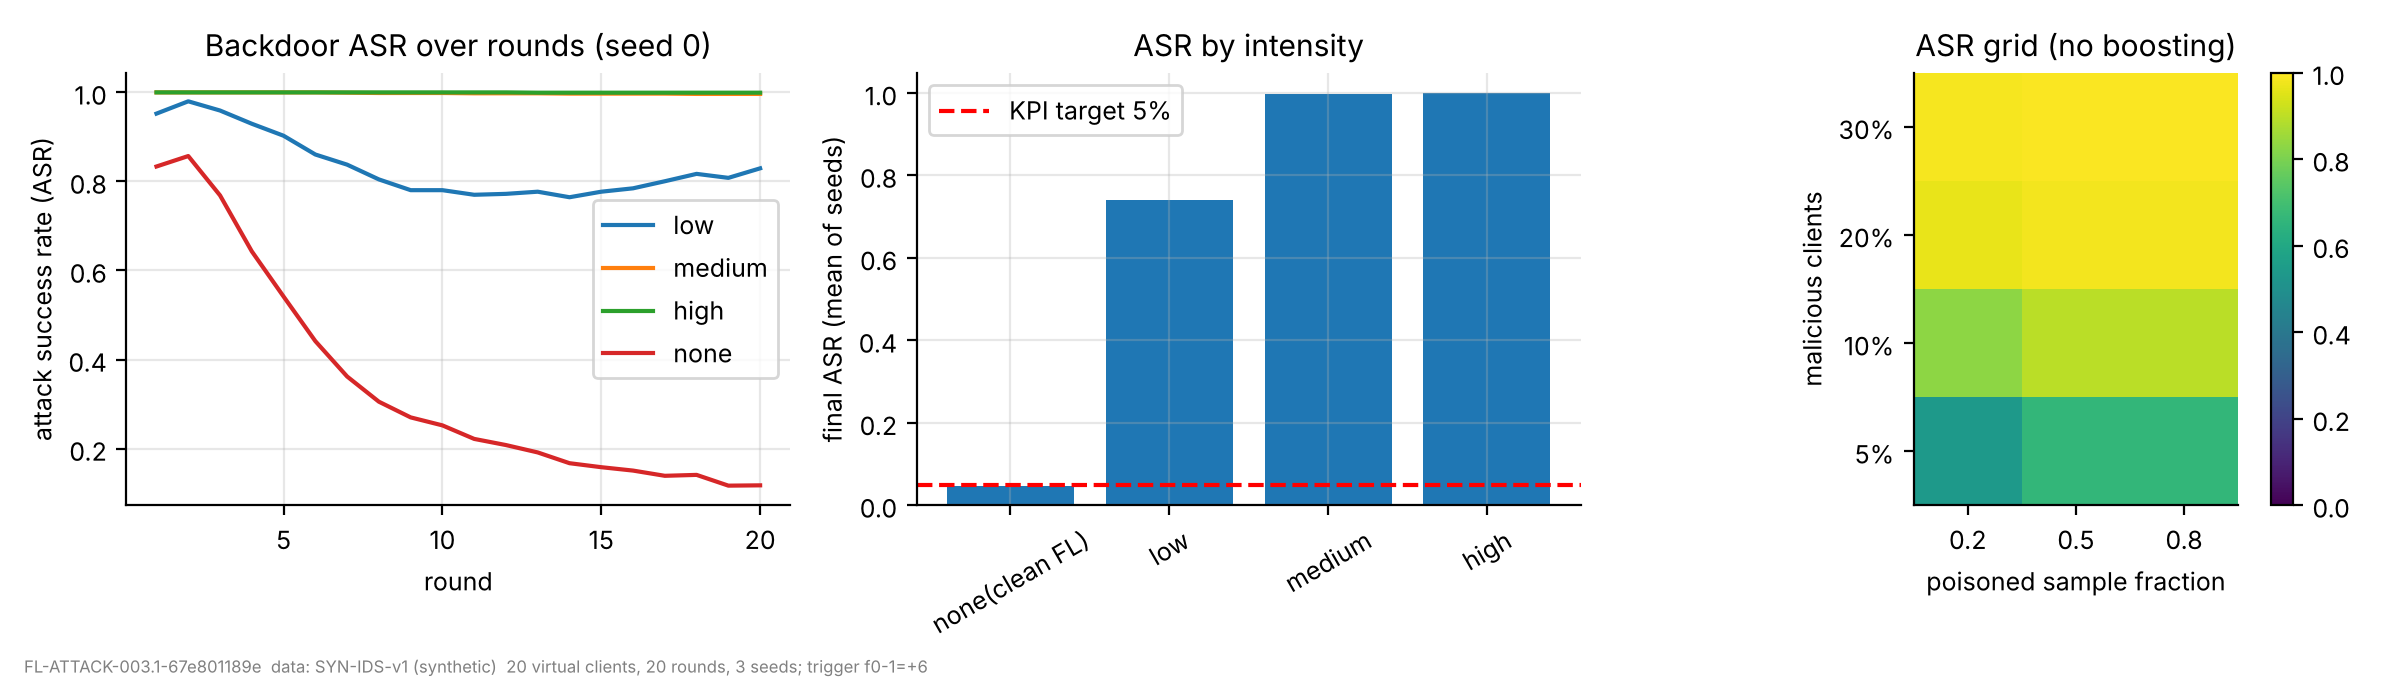

In [10]:
show_fig('task_3_1_backdoor.png')

## 15. Interpretation of results
The numbers are computed in the next cell from the stored data; the text interprets only what that cell prints.

Backdoor ASR is high for all attack levels, while clean accuracy degrades with intensity (printed). Natural trigger ASR on a clean model is reported separately.

In [11]:
d = pd.read_csv(RES / 'task_3_1_summary.csv'); print(d[['level','asr','clean_acc','kpi_asr_lt_5pct']].round(3).to_string(index=False))

         level   asr  clean_acc  kpi_asr_lt_5pct
none(clean FL) 0.046      0.780             True
           low 0.741      0.772            False
        medium 0.997      0.741            False
          high 0.999      0.690            False


## 16. Limitations
- Single trigger family; tabular features not images.
- Synthetic data, virtual clients on one machine, 2 CPU cores, no GPU; no real network. Comm. bytes are logical payload sizes.
- No regulatory/compliance conclusion can be drawn from this notebook.

## 17. Conclusions
Backdoor KPI (<5%) is NOT met without a defence.

**Jira acceptance:** see `docs/fl_attack_003/results_and_discussion.md` for the criterion-by-criterion verdict (MET / PARTIALLY MET / NOT MET).

## 18. References
`bagdasaryan2020`, `sun2019`, `wang2020tail` — details in `docs/fl_attack_003/references.md`.